In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Definición de monedas Euro: (nombre, diámetro_mm, valor_euros, tipo_color)
# tipo_color: "bimetalica", "dorada", "cobriza"
MONEDAS_EURO = [
    ("2 euro",      25.75, 2.00, "bimetalica"),
    ("50 centimos", 24.25, 0.50, "dorada"),
    ("1 euro",      23.25, 1.00, "bimetalica"),
    ("20 centimos", 22.25, 0.20, "dorada"),
    ("5 centimos",  21.25, 0.05, "cobriza"),
    ("10 centimos", 19.75, 0.10, "dorada"),
    ("2 centimos",  18.75, 0.02, "cobriza"),
    ("1 centimo",   16.25, 0.01, "cobriza"),
]

# Colores para visualización según tipo
COLORES_TIPO = {
    "bimetalica": (0, 255, 255),   # Amarillo (BGR)
    "dorada":     (0, 200, 255),    # Naranja (BGR)
    "cobriza":    (0, 100, 200),    # Marrón/cobre (BGR)
    "desconocida": (255, 255, 255), # Blanco
}


In [3]:
def clasificar_color_moneda(img_bgr, cx, cy, radio):
    """
    Clasifica el color de una moneda analizando la región central
    en el espacio HSV.
    
    Las monedas bimetálicas (1€, 2€) tienen una diferencia notable
    de saturación/hue entre su centro y su borde exterior.
    Las cobrizas tienen hue bajo (rojizo) y alta saturación.
    Las doradas tienen hue medio y saturación moderada-alta.
    
    Retorna: "bimetalica", "dorada" o "cobriza"
    """
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, w = img_bgr.shape[:2]
    
    # Máscara circular en la zona central (50% del radio)
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (int(cx), int(cy)), max(1, int(radio * 0.5)), 255, -1)
    mean_hsv = cv2.mean(hsv, mask=mask)[:3]
    hue, sat, val = mean_hsv
    
    # Zona anular exterior (entre 60% y 90% del radio)
    mask_outer = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask_outer, (int(cx), int(cy)), max(1, int(radio * 0.9)), 255, -1)
    mask_inner = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask_inner, (int(cx), int(cy)), max(1, int(radio * 0.6)), 255, -1)
    mask_ring = cv2.subtract(mask_outer, mask_inner)
    mean_hsv_outer = cv2.mean(hsv, mask=mask_ring)[:3]
    
    # Diferencia entre centro y borde
    sat_diff = abs(mean_hsv[1] - mean_hsv_outer[1])
    hue_diff = abs(mean_hsv[0] - mean_hsv_outer[0])
    
    # Bimetálica: gran diferencia de saturación o hue entre centro y borde
    if sat_diff > 25 or hue_diff > 8:
        return "bimetalica"
    
    # Cobriza: hue bajo (rojizo) y alta saturación
    if hue < 12 and sat > 100:
        return "cobriza"
    
    # Dorada: hue entre 12-30 y saturación moderada-alta
    if 12 <= hue <= 30 and sat > 80:
        return "dorada"
    
    # Si baja saturación, probablemente bimetálica (parte plateada)
    if sat < 40:
        return "bimetalica"
    
    return "dorada"


In [4]:
def clasificar_moneda(diametro_mm, tipo_color):
    """
    Clasifica una moneda a partir de su diámetro en mm y su tipo de color.
    Busca la moneda más cercana en diámetro que sea compatible con el color.
    Se penaliza la distancia si el tipo de color no coincide.
    
    Retorna: (nombre, valor_euros)
    """
    mejor_match = None
    mejor_dist = float("inf")
    
    for nombre, diam, valor, color in MONEDAS_EURO:
        dist = abs(diametro_mm - diam)
        
        # Priorizar monedas del mismo tipo de color
        if color == tipo_color:
            dist_efectiva = dist
        else:
            # Penalización por no coincidir el color
            dist_efectiva = dist + 5.0
        
        if dist_efectiva < mejor_dist:
            mejor_dist = dist_efectiva
            mejor_match = (nombre, valor)
    
    return mejor_match


In [5]:
def detectar_monedas_contornos(img_bgr, px_por_mm, umbral=None, area_min=5000):
    """
    Detecta monedas usando umbralizado + contornos.
    El diámetro se estima a partir del área del contorno (diámetro equivalente).
    
    Args:
        img_bgr: Imagen en BGR
        px_por_mm: Relación píxeles por milímetro
        umbral: Umbral fijo (None = Otsu automático)
        area_min: Área mínima de contorno para considerar como moneda
    
    Retorna: (img_resultado, lista_monedas, total_euros)
    """
    img_result = img_bgr.copy()
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Umbralizado
    if umbral is None:
        _, thresh = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:
        _, thresh = cv2.threshold(gris, umbral, 255, cv2.THRESH_BINARY_INV)
    
    # Buscar contornos externos
    contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    monedas_detectadas = []
    total = 0.0
    
    for c in contornos:
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        
        # Centro y radio del círculo envolvente mínimo
        (cx, cy), radio_enclosing = cv2.minEnclosingCircle(c)
        
        # Diámetro equivalente a partir del área (más preciso para formas circulares)
        equiv_diam_px = np.sqrt(4 * area / np.pi)
        radio_px = equiv_diam_px / 2
        
        # Verificar circularidad: relación área / área del círculo envolvente
        circularidad = area / (np.pi * radio_enclosing**2)
        if circularidad < 0.5:  # No es suficientemente circular
            continue
        
        # Convertir a mm
        diametro_mm = equiv_diam_px / px_por_mm
        
        # Clasificar color
        tipo_color = clasificar_color_moneda(img_bgr, cx, cy, radio_px)
        
        # Clasificar moneda
        nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
        total += valor
        
        monedas_detectadas.append({
            "nombre": nombre,
            "valor": valor,
            "centro": (int(cx), int(cy)),
            "radio_px": int(radio_px),
            "diametro_mm": diametro_mm,
            "tipo_color": tipo_color,
            "circularidad": circularidad,
        })
        
        # Dibujar
        color_dibujo = COLORES_TIPO.get(tipo_color, (255, 255, 255))
        cv2.circle(img_result, (int(cx), int(cy)), int(radio_px), color_dibujo, 2)
        cv2.circle(img_result, (int(cx), int(cy)), 3, color_dibujo, -1)
        
        texto = f"{nombre} ({valor:.2f}E)"
        cv2.putText(img_result, texto,
                   (int(cx) - int(radio_px), int(cy) - int(radio_px) - 10),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_dibujo, 1)
        texto_mm = f"{diametro_mm:.1f}mm"
        cv2.putText(img_result, texto_mm,
                   (int(cx) - 20, int(cy) + 5),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    
    # Total
    texto_total = f"Total: {total:.2f} EUR ({len(monedas_detectadas)} monedas)"
    cv2.putText(img_result, texto_total, (10, 30),
               cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    
    return img_result, monedas_detectadas, total


In [6]:
def detectar_monedas_hough(img_bgr, px_por_mm,
                           min_radius_px=15, max_radius_px=200,
                           param1=100, param2=50, min_dist=50,
                           blur_ksize=7):
    """
    Detecta monedas usando la Transformada de Hough para círculos.
    Más adecuada para detección en tiempo real (webcam).
    
    Retorna: (img_resultado, lista_monedas, total_euros)
    """
    img_result = img_bgr.copy()
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris_blur = cv2.medianBlur(gris, blur_ksize)
    
    circulos = cv2.HoughCircles(
        gris_blur,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius_px,
        maxRadius=max_radius_px,
    )
    
    monedas_detectadas = []
    total = 0.0
    
    if circulos is not None:
        circulos = np.uint16(np.around(circulos))
        for circ in circulos[0, :]:
            cx, cy, radio_px = circ
            diametro_mm = (2 * radio_px) / px_por_mm
            tipo_color = clasificar_color_moneda(img_bgr, cx, cy, radio_px)
            nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
            total += valor
            
            monedas_detectadas.append({
                "nombre": nombre,
                "valor": valor,
                "centro": (int(cx), int(cy)),
                "radio_px": int(radio_px),
                "diametro_mm": diametro_mm,
                "tipo_color": tipo_color,
            })
            
            color_dibujo = COLORES_TIPO.get(tipo_color, (255, 255, 255))
            cv2.circle(img_result, (int(cx), int(cy)), int(radio_px), color_dibujo, 2)
            cv2.circle(img_result, (int(cx), int(cy)), 3, color_dibujo, -1)
            texto = f"{nombre} ({valor:.2f}E)"
            cv2.putText(img_result, texto,
                       (int(cx) - int(radio_px), int(cy) - int(radio_px) - 10),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_dibujo, 1)
            texto_mm = f"{diametro_mm:.1f}mm"
            cv2.putText(img_result, texto_mm,
                       (int(cx) - 20, int(cy) + 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    
    texto_total = f"Total: {total:.2f} EUR ({len(monedas_detectadas)} monedas)"
    cv2.putText(img_result, texto_total, (10, 30),
               cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    
    return img_result, monedas_detectadas, total


## Paso 1: Detección en la imagen estática (`Monedas.jpg`)

Cargamos la imagen, aplicamos umbralizado Otsu y detectamos contornos.
Usamos la moneda más grande (2€) como referencia para calibrar la relación píxeles/mm.
El diámetro de cada moneda se estima usando el **diámetro equivalente** a partir del área del contorno,
que es más preciso que el radio del círculo de Hough.


Imagen cargada: (938, 473, 3)


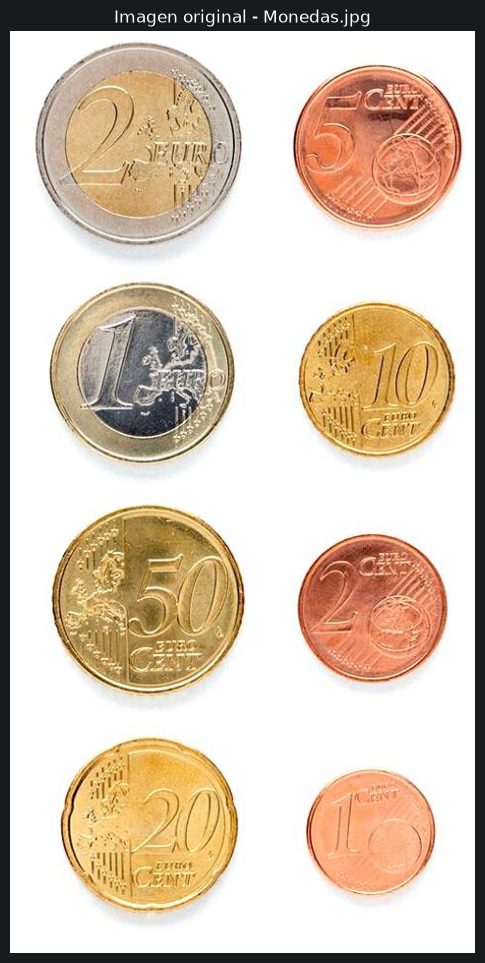

In [7]:
# Cargar imagen
img = cv2.imread("Monedas.jpg")
if img is None:
    raise FileNotFoundError("No se encontró Monedas.jpg")
print(f"Imagen cargada: {img.shape}")

# Mostrar la imagen original
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 12))
plt.imshow(img_rgb)
plt.title("Imagen original - Monedas.jpg")
plt.axis("off")
plt.show()


Umbral Otsu seleccionado: 204.0
Contornos encontrados: 50
Contornos de monedas (área > 5000): 8


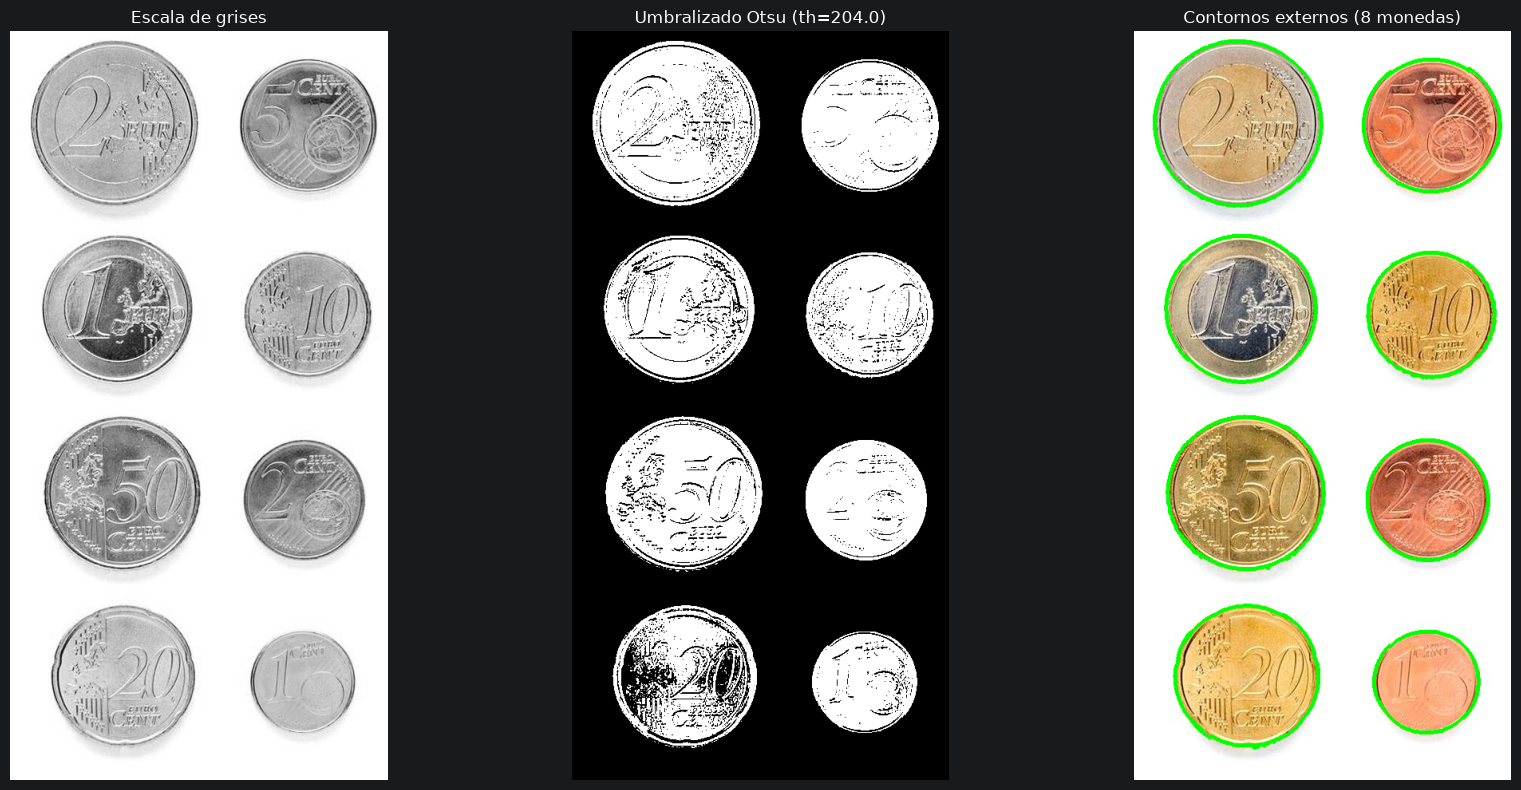

In [8]:
# Convertir a escala de grises
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Umbralizado Otsu
otsu_th, thresh = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Umbral Otsu seleccionado: {otsu_th}")

# Buscar contornos externos
contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f"Contornos encontrados: {len(contornos)}")

# Filtrar por área mínima (eliminar ruido)
contornos_monedas = [c for c in contornos if cv2.contourArea(c) > 5000]
print(f"Contornos de monedas (área > 5000): {len(contornos_monedas)}")

# Visualizar umbralizado y contornos
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

axes[0].imshow(gris, cmap="gray")
axes[0].set_title("Escala de grises")
axes[0].axis("off")

axes[1].imshow(thresh, cmap="gray")
axes[1].set_title(f"Umbralizado Otsu (th={otsu_th})")
axes[1].axis("off")

img_contornos = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
cv2.drawContours(img_contornos, contornos_monedas, -1, (0, 255, 0), 3)
axes[2].imshow(img_contornos)
axes[2].set_title(f"Contornos externos ({len(contornos_monedas)} monedas)")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [9]:
# Calibración: encontrar la moneda más grande (2 euro)
# Calcular diámetro equivalente de cada contorno
diametros_px = []
for c in contornos_monedas:
    area = cv2.contourArea(c)
    equiv_diam = np.sqrt(4 * area / np.pi)
    diametros_px.append(equiv_diam)

# La moneda más grande es la de 2 euro (25.75 mm de diámetro)
max_diam_px = max(diametros_px)
DIAMETRO_REF_MM = 25.75  # 2 euro
px_por_mm = max_diam_px / DIAMETRO_REF_MM

print(f"Calibración:")
print(f"  Moneda de referencia: 2 euro (diámetro = {DIAMETRO_REF_MM} mm)")
print(f"  Diámetro equivalente en píxeles: {max_diam_px:.1f} px")
print(f"  Relación: {px_por_mm:.2f} px/mm")
print()

# Mostrar todos los diámetros encontrados
print("Diámetros equivalentes detectados (mm):")
for d in sorted(diametros_px, reverse=True):
    print(f"  {d/px_por_mm:.1f} mm ({d:.1f} px)")


Calibración:
  Moneda de referencia: 2 euro (diámetro = 25.75 mm)
  Diámetro equivalente en píxeles: 207.2 px
  Relación: 8.05 px/mm

Diámetros equivalentes detectados (mm):
  25.8 mm (207.2 px)
  24.0 mm (192.9 px)
  23.0 mm (184.8 px)
  22.1 mm (177.5 px)
  20.9 mm (167.9 px)
  19.5 mm (157.3 px)
  18.8 mm (150.9 px)
  16.0 mm (128.7 px)


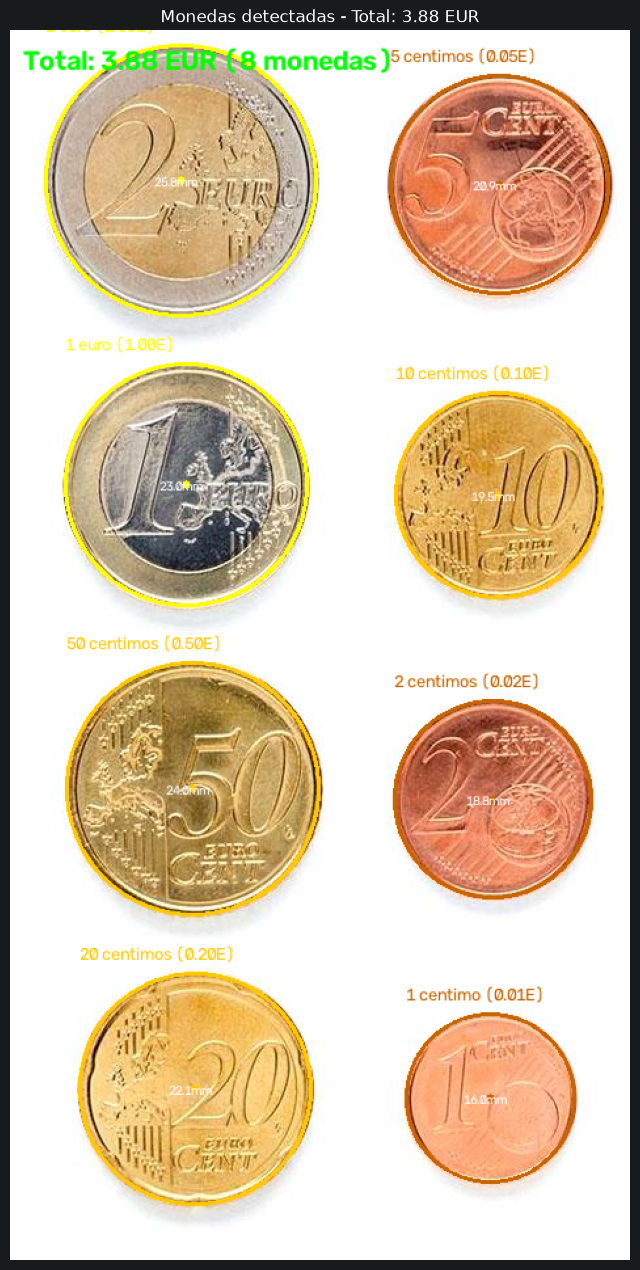


RESUMEN DE MONEDAS DETECTADAS
  1.       1 centimo |  0.01 EUR | diam  16.0 mm | color:     cobriza | circ: 0.96
  2.     20 centimos |  0.20 EUR | diam  22.1 mm | color:      dorada | circ: 0.96
  3.      2 centimos |  0.02 EUR | diam  18.8 mm | color:     cobriza | circ: 0.98
  4.     50 centimos |  0.50 EUR | diam  24.0 mm | color:      dorada | circ: 0.96
  5.     10 centimos |  0.10 EUR | diam  19.5 mm | color:      dorada | circ: 0.97
  6.          1 euro |  1.00 EUR | diam  23.0 mm | color:  bimetalica | circ: 0.96
  7.      5 centimos |  0.05 EUR | diam  20.9 mm | color:     cobriza | circ: 0.96
  8.          2 euro |  2.00 EUR | diam  25.8 mm | color:  bimetalica | circ: 0.97
-----------------------------------------------------------------
  TOTAL: 3.88 EUR  (8 monedas)
  ESPERADO: 3.88 EUR (8 monedas)


In [11]:
# Detección y clasificación de todas las monedas
img_resultado, monedas, total = detectar_monedas_contornos(
    img, px_por_mm, area_min=5000
)

# Mostrar resultados
plt.figure(figsize=(8, 16))
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.title(f"Monedas detectadas - Total: {total:.2f} EUR")
plt.axis("off")
plt.show()

# Resumen detallado
print("\n" + "="*65)
print("RESUMEN DE MONEDAS DETECTADAS")
print("="*65)
for i, m in enumerate(monedas):
    print(f'  {i+1}. {m["nombre"]:>15s} | {m["valor"]:>5.2f} EUR | '
          f'diam {m["diametro_mm"]:>5.1f} mm | color: {m["tipo_color"]:>11s} | '
          f'circ: {m["circularidad"]:.2f}')
print("-"*65)
print(f"  TOTAL: {total:.2f} EUR  ({len(monedas)} monedas)")
print(f"  ESPERADO: 3.88 EUR (8 monedas)")
print("="*65)


## Paso 2: Demostrador en vivo (Webcam)

El siguiente código captura vídeo de la webcam y detecta monedas en tiempo real
usando la Transformada de Hough para círculos.

### Instrucciones:
1. Ejecuta la celda siguiente.
2. Se abrirá una ventana con la imagen de la webcam.
3. **Calibra**: pulsa `c` y haz clic en una moneda de 1€, o pulsa `a` para auto-calibración (la moneda más grande = 2€).
4. La detección y clasificación se realizan continuamente.
5. Pulsa `q` o `ESC` para salir.

### Controles:
| Tecla | Acción |
|-------|--------|
| `c` | Modo calibración (clic en moneda de 1€) |
| `a` | Auto-calibración (moneda más grande = 2€) |
| `+`/`-` | Ajustar sensibilidad del detector |
| `q`/`ESC` | Salir |


In [14]:
def demo_webcam():
    """Demostrador en vivo de detección y conteo de monedas con webcam."""
    cap = cv2.VideoCapture(1)
    if not cap.isOpened():
        print("Error: No se pudo abrir la webcam.")
        return
    
    px_por_mm_live = None
    modo_calibracion = False
    clicked_point_live = None
    param2_hough = 50
    
    def on_mouse(event, x, y, flags, param):
        nonlocal clicked_point_live
        if event == cv2.EVENT_LBUTTONDOWN and modo_calibracion:
            clicked_point_live = (x, y)
    
    cv2.namedWindow("Detector de Monedas", cv2.WINDOW_NORMAL)
    cv2.setMouseCallback("Detector de Monedas", on_mouse)
    
    print("Controles:")
    print("  c - Modo calibración (clic en moneda de 1 euro)")
    print("  a - Calibración automática (moneda más grande = 2 euro)")
    print("  +/- - Ajustar sensibilidad")
    print("  q/ESC - Salir")
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        display_frame = frame.copy()
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gris_blur = cv2.medianBlur(gris, 7)
        
        # Parámetros adaptativos según resolución
        h_frame, w_frame = frame.shape[:2]
        min_r = max(15, int(min(h_frame, w_frame) * 0.03))
        max_r = int(min(h_frame, w_frame) * 0.25)
        min_d = max(30, int(min(h_frame, w_frame) * 0.08))
        
        # Detectar círculos con Hough
        circulos_live = cv2.HoughCircles(
            gris_blur,
            cv2.HOUGH_GRADIENT,
            dp=1,
            minDist=min_d,
            param1=100,
            param2=param2_hough,
            minRadius=min_r,
            maxRadius=max_r,
        )
        
        # Modo calibración
        if modo_calibracion:
            cv2.putText(display_frame, "CALIBRACION: Clic en moneda de 1 euro",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            
            if clicked_point_live is not None and circulos_live is not None:
                best_dist = float("inf")
                best_radio = None
                for c in circulos_live[0]:
                    d = np.sqrt((c[0]-clicked_point_live[0])**2 + 
                               (c[1]-clicked_point_live[1])**2)
                    if d < best_dist:
                        best_dist = d
                        best_radio = c[2]
                if best_radio is not None:
                    px_por_mm_live = (2 * best_radio) / 23.25  # 1 euro
                    print(f"Calibrado con 1 euro: {px_por_mm_live:.2f} px/mm")
                modo_calibracion = False
                clicked_point_live = None
        
        # Si está calibrado, clasificar monedas
        if px_por_mm_live is not None and circulos_live is not None:
            total_live = 0.0
            n_monedas = 0
            for circ in circulos_live[0]:
                cx, cy, radio_px = circ
                diametro_mm = (2 * radio_px) / px_por_mm_live
                tipo_color = clasificar_color_moneda(frame, cx, cy, radio_px)
                nombre, valor = clasificar_moneda(diametro_mm, tipo_color)
                total_live += valor
                n_monedas += 1
                
                color_d = COLORES_TIPO.get(tipo_color, (255, 255, 255))
                cv2.circle(display_frame, (int(cx), int(cy)), int(radio_px), color_d, 2)
                cv2.circle(display_frame, (int(cx), int(cy)), 3, color_d, -1)
                cv2.putText(display_frame, f"{nombre} ({valor:.2f}E)",
                           (int(cx)-int(radio_px), int(cy)-int(radio_px)-10),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.4, color_d, 1)
            
            cv2.putText(display_frame, 
                       f"Total: {total_live:.2f} EUR ({n_monedas} monedas)",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        elif px_por_mm_live is None:
            cv2.putText(display_frame, "Sin calibrar. Pulsa c o a",
                       (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            # Dibujar círculos sin clasificar
            if circulos_live is not None:
                for circ in circulos_live[0]:
                    cv2.circle(display_frame, (int(circ[0]), int(circ[1])),
                             int(circ[2]), (200, 200, 200), 1)
        
        # Info sensibilidad
        cv2.putText(display_frame, f"Sensibilidad: {param2_hough} (+/-)",
                   (10, h_frame - 10), cv2.FONT_HERSHEY_SIMPLEX, 
                   0.5, (200, 200, 200), 1)
        
        cv2.imshow("Detector de Monedas", display_frame)
        
        key = cv2.waitKey(30) & 0xFF
        if key == ord("q") or key == 27:  # q o ESC
            break
        elif key == ord("c"):
            modo_calibracion = True
            clicked_point_live = None
            print("Modo calibración. Haz clic en moneda de 1 euro.")
        elif key == ord("a"):
            if circulos_live is not None:
                radios_live = circulos_live[0][:, 2]
                radio_max = np.max(radios_live)
                px_por_mm_live = (2 * radio_max) / 25.75
                print(f"Auto-calibrado (2 euro): {px_por_mm_live:.2f} px/mm")
        elif key == ord("+") or key == ord("="):
            param2_hough = min(100, param2_hough + 5)
            print(f"Sensibilidad (param2): {param2_hough}")
        elif key == ord("-"):
            param2_hough = max(10, param2_hough - 5)
            print(f"Sensibilidad (param2): {param2_hough}")
    
    cap.release()
    cv2.destroyAllWindows()
    print("Webcam cerrada.")

# Ejecutar el demostrador
demo_webcam()


Controles:
  c - Modo calibración (clic en moneda de 1 euro)
  a - Calibración automática (moneda más grande = 2 euro)
  +/- - Ajustar sensibilidad
  q/ESC - Salir
Modo calibración. Haz clic en moneda de 1 euro.
Calibrado con 1 euro: 2.58 px/mm
Sensibilidad (param2): 45
Auto-calibrado (2 euro): 2.61 px/mm
Auto-calibrado (2 euro): 2.52 px/mm
Sensibilidad (param2): 40
Sensibilidad (param2): 45
Auto-calibrado (2 euro): 2.45 px/mm
Sensibilidad (param2): 40
Sensibilidad (param2): 35
Sensibilidad (param2): 30
Sensibilidad (param2): 25
Sensibilidad (param2): 30
Sensibilidad (param2): 35
Sensibilidad (param2): 40
Sensibilidad (param2): 45
Sensibilidad (param2): 50
Sensibilidad (param2): 55
Sensibilidad (param2): 60
Sensibilidad (param2): 55
Sensibilidad (param2): 50
Sensibilidad (param2): 45
Sensibilidad (param2): 40
Sensibilidad (param2): 35
Sensibilidad (param2): 30
Sensibilidad (param2): 35
Modo calibración. Haz clic en moneda de 1 euro.
Calibrado con 1 euro: 2.45 px/mm
Modo calibración. Ha